<a href="https://colab.research.google.com/github/tigre71agro-ctrl/Desercion-escolar/blob/master/notebooks/S56_red_con_mis_datos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# INFORME DE LA UNIDAD I

**Preparación, documentación y análisis exploratorio de datos sobre deserción universitaria**

**Curso:** Ciencia de Datos e Inteligencia Artificial Aplicada

**Elaborado por:**

- Juan Carlos Santos Prado
- María del Pilar Anacleto Pinedo
- Lucy Emilia Torres Carrera

**Fuente de datos:** UCI Machine Learning Repository — Dataset 697

**Año:** 2026

In [2]:

# 1. Lectura de datos

import pandas as pd

url = "https://raw.githubusercontent.com/tigre71agro-ctrl/Desercion-escolar/master/data/raw/data.csv"

datos = pd.read_csv(url, sep=";")

# Estructura de los datos
print(datos.shape)

# Primeras observaciones
display(datos.head())


(4424, 37)


,Marital status,Application mode,Application order,Course,Daytime/evening attendance\t,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


### 1.1. Estructura inicial del conjunto de datos

La importación del conjunto de datos *Predict Students' Dropout and Academic Success*, procedente del repositorio UCI Machine Learning Repository, permitió identificar 4424 observaciones y 37 variables. Cada registro corresponde a un estudiante, mientras que las variables contienen información académica, demográfica y socioeconómica.

La estructura comprende 36 variables explicativas y una variable respuesta denominada *Target*, que clasifica la situación académica de los estudiantes en tres categorías: abandono (*Dropout*), matriculados (*Enrolled*) y graduados (*Graduate*).

Esta primera revisión permitió comprobar que el archivo fue importado correctamente en Google Colab y establecer la estructura inicial para los posteriores procedimientos de auditoría, preparación y análisis exploratorio.

In [3]:

# 2. Auditoria de datos

# Valores faltantes
print("Valores faltantes:", datos.isna().sum().sum())

# Registros duplicados
print("Duplicados:", datos.duplicated().sum())

# Distribucion de la situacion academica
print("\nFrecuencias:")
print(datos["Target"].value_counts())

# Porcentajes
print("\nPorcentajes:")
print(datos["Target"].value_counts(normalize=True).mul(100).round(2))


Valores faltantes: 0
Duplicados: 0

Frecuencias:
Target
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64

Porcentajes:
Target
Graduate    49.93
Dropout     32.12
Enrolled    17.95
Name: proportion, dtype: float64


### Interpretación de la auditoría inicial

La auditoría del conjunto de datos permitió verificar que las 4424 observaciones no presentan valores faltantes ni registros exactamente duplicados. Estos resultados evidencian una adecuada completitud de la información, aunque todavía es necesario revisar la consistencia y plausibilidad de las variables.

Respecto a la situación académica, el 49,93 % de los estudiantes corresponde a graduados, el 32,12 % a estudiantes que abandonaron sus estudios y el 17,95 % a estudiantes matriculados. Esta distribución muestra diferencias en la representación de las categorías, aspecto que deberá considerarse en las siguientes etapas del análisis y modelado.

In [4]:

# 3. Validacion y consistencia de los datos

# Edad de ingreso
print("Edad de ingreso")
print(datos["Age at enrollment"].describe())

# Nota de admision
print("\nNota de admision")
print(datos["Admission grade"].describe())

# Calificaciones por semestre
print("\nPrimer semestre")
print(datos["Curricular units 1st sem (grade)"].describe())

print("\nSegundo semestre")
print(datos["Curricular units 2nd sem (grade)"].describe())

# Comprobaciones de consistencia
print("\nEdades no validas:",
      (datos["Age at enrollment"] <= 0).sum())

print("Inconsistencias primer semestre:",
      (datos["Curricular units 1st sem (approved)"] >
       datos["Curricular units 1st sem (enrolled)"]).sum())

print("Inconsistencias segundo semestre:",
      (datos["Curricular units 2nd sem (approved)"] >
       datos["Curricular units 2nd sem (enrolled)"]).sum())


Edad de ingreso
count    4424.000000
mean       23.265145
std         7.587816
min        17.000000
25%        19.000000
50%        20.000000
75%        25.000000
max        70.000000
Name: Age at enrollment, dtype: float64

Nota de admision
count    4424.000000
mean      126.978119
std        14.482001
min        95.000000
25%       117.900000
50%       126.100000
75%       134.800000
max       190.000000
Name: Admission grade, dtype: float64

Primer semestre
count    4424.000000
mean       10.640822
std         4.843663
min         0.000000
25%        11.000000
50%        12.285714
75%        13.400000
max        18.875000
Name: Curricular units 1st sem (grade), dtype: float64

Segundo semestre
count    4424.000000
mean       10.230206
std         5.210808
min         0.000000
25%        10.750000
50%        12.200000
75%        13.333333
max        18.571429
Name: Curricular units 2nd sem (grade), dtype: float64

Edades no validas: 0
Inconsistencias primer semestre: 0
Inconsistencia

### 3.1. Interpretación de la validación y consistencia

El análisis descriptivo permitió identificar una edad promedio de ingreso de 23,27 años, con valores comprendidos entre 17 y 70 años. La calificación media de admisión fue de 126,98 puntos, mientras que las calificaciones promedio del primer y segundo semestre fueron de 10,64 y 10,23 puntos, respectivamente.

Las comprobaciones de consistencia no identificaron edades no positivas ni registros en los que el número de asignaturas aprobadas superara al de asignaturas matriculadas. Estos resultados indican que las variables evaluadas cumplen las reglas básicas de coherencia establecidas para el análisis.

Sin embargo, la presencia de edades elevadas y calificaciones iguales a cero requiere una revisión adicional para determinar si corresponden a situaciones académicas legítimas o a posibles problemas de registro. En consecuencia, no se considera pertinente eliminar o modificar estas observaciones sin una evaluación previa.

In [5]:

# 4. Revision de valores extremos y ceros

print("Estudiantes mayores de 40 años:",
      (datos["Age at enrollment"] > 40).sum())

print("Sin asignaturas en el primer semestre:",
      (datos["Curricular units 1st sem (enrolled)"] == 0).sum())

print("Nota cero en el primer semestre:",
      (datos["Curricular units 1st sem (grade)"] == 0).sum())

print("Sin asignaturas en el segundo semestre:",
      (datos["Curricular units 2nd sem (enrolled)"] == 0).sum())

print("Nota cero en el segundo semestre:",
      (datos["Curricular units 2nd sem (grade)"] == 0).sum())


Estudiantes mayores de 40 años: 225
Sin asignaturas en el primer semestre: 180
Nota cero en el primer semestre: 718
Sin asignaturas en el segundo semestre: 180
Nota cero en el segundo semestre: 870


### 4.1. Interpretación de valores extremos y calificaciones cero

Se identificaron 225 estudiantes mayores de 40 años, así como 180 registros sin asignaturas matriculadas en cada semestre. Además, se encontraron 718 calificaciones iguales a cero en el primer semestre y 870 en el segundo. Estos valores requieren verificar su relación con la matrícula académica antes de decidir su tratamiento, evitando eliminar observaciones sin justificación.

In [6]:

# 5. Relacion entre matricula y calificaciones

for sem in ["1st", "2nd"]:
    matricula = datos[f"Curricular units {sem} sem (enrolled)"] == 0
    nota = datos[f"Curricular units {sem} sem (grade)"] == 0

    print(f"\nSemestre {sem}")
    print(pd.crosstab(matricula, nota))



Semestre 1st
Curricular units 1st sem (grade)     False  True 
Curricular units 1st sem (enrolled)              
False                                 3706    538
True                                     0    180

Semestre 2nd
Curricular units 2nd sem (grade)     False  True 
Curricular units 2nd sem (enrolled)              
False                                 3554    690
True                                     0    180


### 5.1. Interpretación

Se identificaron 180 estudiantes sin asignaturas matriculadas y con calificación cero en cada semestre. Además, 538 estudiantes del primer semestre y 690 del segundo presentaron calificación cero pese a tener asignaturas matriculadas. Estos resultados justifican conservar los registros originales y evitar modificaciones sin verificar previamente su significado académico.

In [7]:

# 6. Preparacion de datos

import numpy as np

datos_curados = datos.copy()

for sem, nombre in [("1st", "tasa_aprobacion_1"),
                    ("2nd", "tasa_aprobacion_2")]:

    matriculadas = datos[f"Curricular units {sem} sem (enrolled)"]
    aprobadas = datos[f"Curricular units {sem} sem (approved)"]

    datos_curados[nombre] = np.where(
        matriculadas > 0,
        aprobadas / matriculadas.replace(0, np.nan),
        np.nan
    )

print("Dimensiones:", datos_curados.shape)

display(
    datos_curados[
        ["tasa_aprobacion_1", "tasa_aprobacion_2"]
    ].describe()
)

print("\nValores no calculables:")
print(datos_curados[
    ["tasa_aprobacion_1", "tasa_aprobacion_2"]
].isna().sum())


Dimensiones: (4424, 39)


,tasa_aprobacion_1,tasa_aprobacion_2
count,4244.000000,4244.000000
mean,0.727484,0.688364
std,0.342821,0.365513
min,0.000000,0.000000
25%,0.600000,0.500000
50%,0.857143,0.833333
75%,1.000000,1.000000
max,1.000000,1.000000



Valores no calculables:
tasa_aprobacion_1    180
tasa_aprobacion_2    180
dtype: int64


### 7.1. Interpretación preparacion de datos

Se construyeron dos indicadores de aprobación académica, con promedios de 72,75 % para el primer semestre y 68,84 % para el segundo. Se conservaron las 4424 observaciones y se incorporaron dos variables derivadas, alcanzando un total de 39. En cada indicador, 180 registros quedaron sin tasa calculable debido a la ausencia de asignaturas matriculadas.

In [8]:

# 8. Validacion y almacenamiento

from pathlib import Path

# Validar dimensiones y tasas
assert datos_curados.shape == (4424, 39)

for variable in ["tasa_aprobacion_1", "tasa_aprobacion_2"]:
    assert datos_curados[variable].dropna().between(0, 1).all()

print("Validacion correcta")

# Crear carpeta de resultados
Path("data/processed").mkdir(parents=True, exist_ok=True)

# Guardar dataset procesado
datos_curados.to_csv(
    "data/processed/estudiantes_curados.csv",
    index=False
)

print("Archivo guardado correctamente")


Validacion correcta
Archivo guardado correctamente


,count,mean,median
Target,,,
Dropout,1344,40.60,40.0
Enrolled,766,71.35,80.0
Graduate,2134,93.50,100.0



Valores no calculables:
Target
Dropout     77
Enrolled    28
Graduate    75
Name: tasa_aprobacion_1, dtype: int64


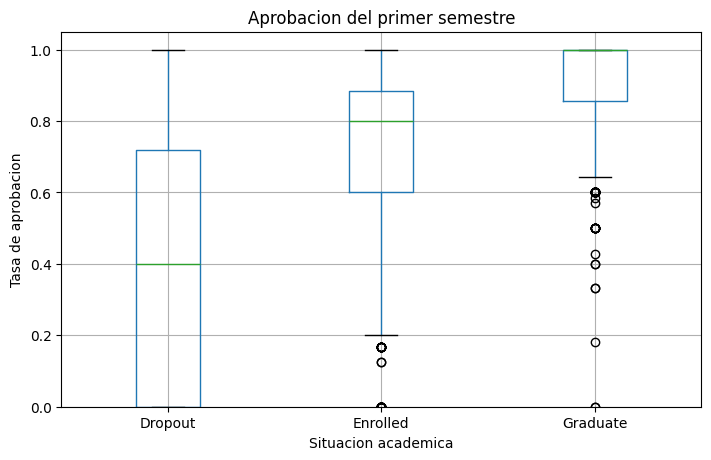

In [9]:

# 8. Rendimiento academico y situacion del estudiante

import matplotlib.pyplot as plt

# Media y mediana por grupo
resumen = datos_curados.groupby("Target")["tasa_aprobacion_1"].agg(
    ["count", "mean", "median"]
)

resumen["mean"] = resumen["mean"] * 100
resumen["median"] = resumen["median"] * 100

display(resumen.round(2))

# Casos sin tasa calculable
print("\nValores no calculables:")
print(datos_curados.groupby("Target")["tasa_aprobacion_1"]
      .apply(lambda x: x.isna().sum()))

# Grafico de cajas
datos_curados.boxplot(
    column="tasa_aprobacion_1",
    by="Target",
    figsize=(8, 5)
)

plt.title("Aprobacion del primer semestre")
plt.suptitle("")
plt.xlabel("Situacion academica")
plt.ylabel("Tasa de aprobacion")
plt.ylim(0, 1.05)
plt.show()


### 9.1. Rendimiento académico y situación del estudiante

Los estudiantes graduados presentaron una tasa media de aprobación del 93,50 %, seguida de los matriculados (71,35 %) y quienes abandonaron sus estudios (40,60 %). El diagrama de cajas muestra una mayor dispersión entre los estudiantes que abandonaron sus estudios. Estos resultados respaldan descriptivamente la primera hipótesis, aunque no permiten establecer causalidad ni significación estadística.

,count,mean,median
Target,,,
Dropout,1421,26.07,23.0
Enrolled,794,22.37,20.0
Graduate,2209,21.78,19.0


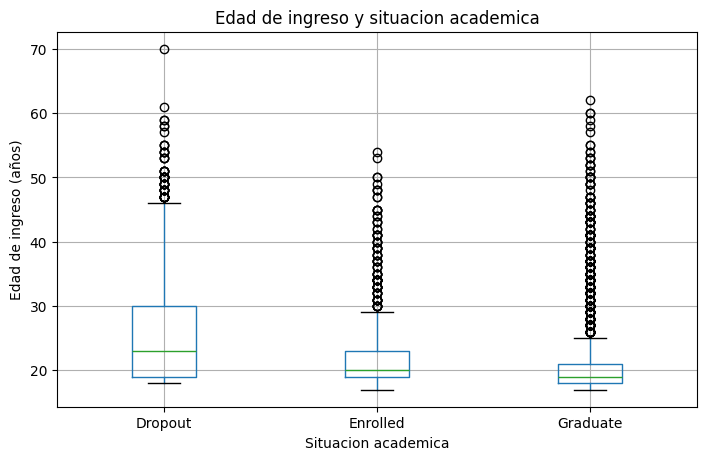

In [10]:

# 9. Edad de ingreso y situacion academica

# Estadisticas por grupo
resumen_edad = datos_curados.groupby("Target")["Age at enrollment"].agg(
    ["count", "mean", "median"]
)

display(resumen_edad.round(2))

# Grafico de cajas
datos_curados.boxplot(
    column="Age at enrollment",
    by="Target",
    figsize=(8, 5)
)

plt.title("Edad de ingreso y situacion academica")
plt.suptitle("")
plt.xlabel("Situacion academica")
plt.ylabel("Edad de ingreso (años)")
plt.show()


### 10.1. Edad de ingreso y situación académica

Los estudiantes que abandonaron sus estudios presentaron una edad media de ingreso de 26,07 años, superior a la de los matriculados (22,37 años) y graduados (21,78 años). El gráfico evidencia una mayor dispersión de edades en el grupo de abandono. Estos resultados apoyan descriptivamente la segunda hipótesis, aunque no permiten establecer una relación causal.

Target,Dropout,Enrolled,Graduate
Sin beca,1287,664,1374
Con beca,134,130,835


Target,Dropout,Enrolled,Graduate
Sin beca,38.71,19.97,41.32
Con beca,12.19,11.83,75.98


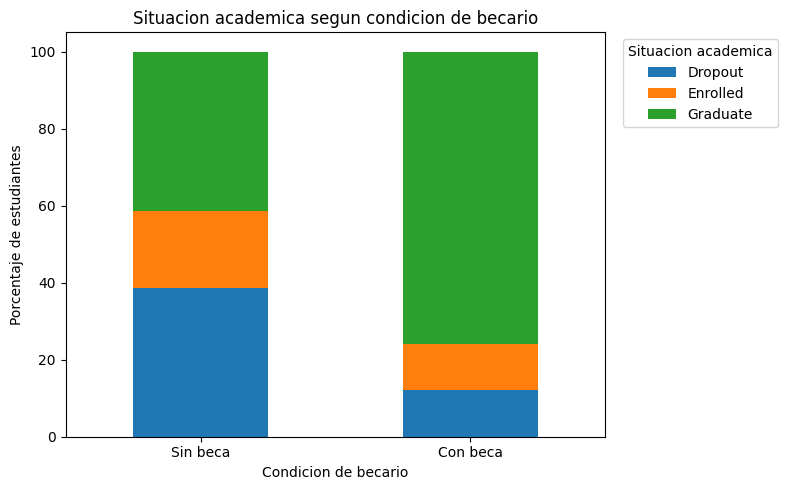

In [11]:

# 10. Condicion de becario y situacion academica

# Tabla de frecuencias
tabla_beca = pd.crosstab(
    datos_curados["Scholarship holder"],
    datos_curados["Target"]
)

tabla_beca.index = ["Sin beca", "Con beca"]
display(tabla_beca)

# Porcentajes por grupo
porcentaje_beca = tabla_beca.div(
    tabla_beca.sum(axis=1), axis=0
) * 100

display(porcentaje_beca.round(2))

# Grafico comparativo
porcentaje_beca.plot(
    kind="bar",
    stacked=True,
    figsize=(8, 5)
)

plt.title("Situacion academica segun condicion de becario")
plt.xlabel("Condicion de becario")
plt.ylabel("Porcentaje de estudiantes")
plt.xticks(rotation=0)
plt.legend(title="Situacion academica",
           bbox_to_anchor=(1.02, 1),
           loc="upper left")
plt.tight_layout()
plt.show()


### 11.1. Condición de becario y situación académica

Los estudiantes con beca presentaron una mayor proporción de graduación (75,98 %) y menor abandono (12,19 %) respecto a los estudiantes sin beca, cuyos porcentajes fueron 41,32 % y 38,71 %, respectivamente. Estos hallazgos respaldan descriptivamente la tercera hipótesis y sugieren una asociación entre la condición de becario y la situación académica, sin establecer una relación causal.

,count,mean,median
Target,,,
Dropout,1421,124.96,123.6
Enrolled,794,125.53,124.1
Graduate,2209,128.79,127.4


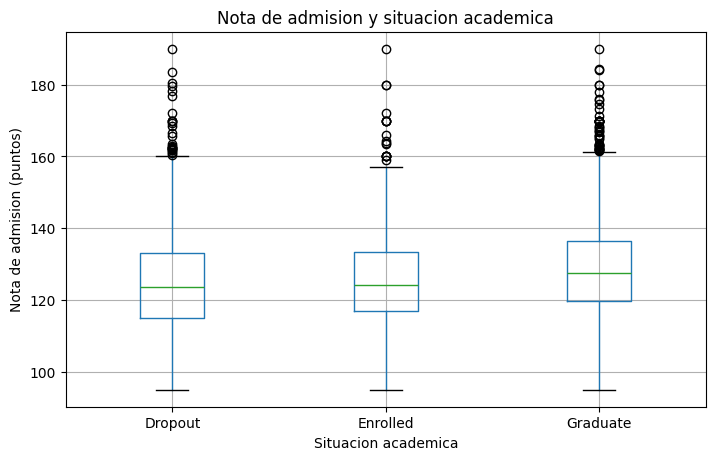

In [12]:

# 11. Nota de admision y situacion academica

# Estadisticas por grupo
resumen_admision = datos_curados.groupby("Target")["Admission grade"].agg(
    ["count", "mean", "median"]
)

display(resumen_admision.round(2))

# Grafico de cajas
datos_curados.boxplot(
    column="Admission grade",
    by="Target",
    figsize=(8, 5)
)

plt.title("Nota de admision y situacion academica")
plt.suptitle("")
plt.xlabel("Situacion academica")
plt.ylabel("Nota de admision (puntos)")
plt.show()


### 12.1. Nota de admisión y situación académica

Los estudiantes graduados presentaron una nota media de admisión de 128,79 puntos, superior a la de los matriculados (125,53) y quienes abandonaron sus estudios (124,96). Aunque se observaron diferencias entre los grupos, el gráfico muestra un considerable solapamiento de las distribuciones. Estos resultados apoyan descriptivamente la cuarta hipótesis, pero sugieren una capacidad de diferenciación limitada de esta variable por sí sola.

In [13]:

# 12. Registro de decisiones

decisiones = pd.DataFrame({
    "Decision": [
        "Conservar registros",
        "Conservar edades elevadas",
        "Mantener calificaciones cero",
        "Crear tasas de aprobacion",
        "Asignar NaN sin matricula"
    ],
    "Justificacion": [
        "No se encontraron faltantes ni duplicados",
        "Las edades pueden corresponder a estudiantes adultos",
        "No se comprobo que fueran errores",
        "Permite comparar el rendimiento academico",
        "Evita divisiones entre cero"
    ],
    "Alternativa descartada": [
        "Eliminar observaciones",
        "Excluir mayores de 40 años",
        "Imputar las calificaciones",
        "Utilizar solo asignaturas aprobadas",
        "Asignar tasa igual a cero"
    ],
    "Efecto": [
        "Se conservan 4424 registros",
        "Se conservan 225 casos",
        "No se modifican las notas",
        "Se agregan 2 variables",
        "180 NaN por semestre"
    ]
})

display(decisiones)

# Guardar registro
from pathlib import Path
Path("documentacion").mkdir(exist_ok=True)

decisiones.to_csv(
    "documentacion/registro_decisiones.csv",
    index=False,
    encoding="utf-8-sig"
)


,Decision,Justificacion,Alternativa descartada,Efecto
0,Conservar registros,No se encontraron faltantes ni duplicados,Eliminar observaciones,Se conservan 4424 registros
1,Conservar edades elevadas,Las edades pueden corresponder a estudiantes a...,Excluir mayores de 40 años,Se conservan 225 casos
2,Mantener calificaciones cero,No se comprobo que fueran errores,Imputar las calificaciones,No se modifican las notas
3,Crear tasas de aprobacion,Permite comparar el rendimiento academico,Utilizar solo asignaturas aprobadas,Se agregan 2 variables
4,Asignar NaN sin matricula,Evita divisiones entre cero,Asignar tasa igual a cero,180 NaN por semestre


Las decisiones de preparación permitieron conservar las 4424 observaciones originales e incorporar dos indicadores de aprobación académica. Se evitaron modificaciones injustificadas y se documentaron las transformaciones realizadas para garantizar la trazabilidad y reproducibilidad del análisis.

In [14]:

# 13. Diccionario de datos

url_dic = "https://raw.githubusercontent.com/tigre71agro-ctrl/Desercion-escolar/master/documentacion/diccionario_datos.csv"

diccionario = pd.read_csv(
    url_dic,
    sep=";",
    encoding="utf-8-sig"
)

# Verificar dimensiones
print(diccionario.shape)

# Mostrar primeras variables
display(diccionario.head())

# Verificar variables documentadas
print(set(diccionario["variable"]) == set(datos_curados.columns))


(39, 7)


,variable,descripcion,tipo,unidad_escala,valores_validos,fuente,transformacion
0,Marital status,Por documentar,integer,Por documentar,Por verificar,UCI - dataset 697,Sin modificacion
1,Application mode,Por documentar,integer,Por documentar,Por verificar,UCI - dataset 697,Sin modificacion
2,Application order,Por documentar,integer,Por documentar,Por verificar,UCI - dataset 697,Sin modificacion
3,Course,Por documentar,integer,Por documentar,Por verificar,UCI - dataset 697,Sin modificacion
4,Daytime/evening attendance\t,Por documentar,integer,Por documentar,Por verificar,UCI - dataset 697,Sin modificacion


True


In [15]:

# Revision del diccionario

for campo in ["descripcion", "unidad_escala", "valores_validos"]:
    pendientes = diccionario[campo].isin(
        ["Por documentar", "Por verificar"]
    ).sum()
    print(campo, ":", pendientes, "pendientes")


descripcion : 37 pendientes
unidad_escala : 37 pendientes
valores_validos : 37 pendientes


In [16]:

# 14. Consultar la documentacion oficial

!pip -q install ucimlrepo

from ucimlrepo import fetch_ucirepo

base_uci = fetch_ucirepo(id=697)
variables_uci = base_uci.variables

# Comprobar informacion disponible
print("Dimensiones:", variables_uci.shape)

display(variables_uci.head())


Dimensiones: (37, 7)


,name,role,type,demographic,description,units,missing_values
0,Marital Status,Feature,Integer,Marital Status,1 – single 2 – married 3 – widower 4 – divorce...,None,no
1,Application mode,Feature,Integer,None,1 - 1st phase - general contingent 2 - Ordinan...,None,no
2,Application order,Feature,Integer,None,Application order (between 0 - first choice; a...,None,no
3,Course,Feature,Integer,None,33 - Biofuel Production Technologies 171 - Ani...,None,no
4,Daytime/evening attendance,Feature,Integer,None,1 – daytime 0 - evening,None,no


In [17]:

# 15. Comparacion de nombres de variables

import re

def normalizar_nombre(x):
    x = str(x).replace("\\t", " ")
    return re.sub(r"\s+", " ", x).strip().lower()

nombres_datos = [normalizar_nombre(x) for x in datos.columns]
nombres_uci = [normalizar_nombre(x) for x in variables_uci["name"]]

# Variables que no coinciden
diferencias = set(nombres_datos) - set(nombres_uci)

print("Variables originales:", len(nombres_datos))
print("Variables documentadas:", len(nombres_uci))
print("Nombres sin coincidencia:", diferencias)


Variables originales: 37
Variables documentadas: 37
Nombres sin coincidencia: set()


In [18]:

# 16. Completar diccionario con información de UCI

metadata = variables_uci.copy()
metadata["clave"] = metadata["name"].map(normalizar_nombre)
metadata = metadata.set_index("clave")

for i, fila in diccionario.iterrows():
    nombre = fila["variable"]
    clave = normalizar_nombre(nombre)

    if clave not in metadata.index:
        continue

    info = metadata.loc[clave]

    # Descripcion oficial
    descripcion = info["description"]
    diccionario.at[i, "descripcion"] = (
        str(descripcion) if pd.notna(descripcion)
        else "No especificada por UCI"
    )

    # Unidad o escala documentada
    unidad = info["units"]
    diccionario.at[i, "unidad_escala"] = (
        str(unidad) if pd.notna(unidad)
        else "Unidad no especificada por UCI"
    )

    # Valores observados en la base
    valores = datos[nombre].dropna().unique()

    if len(valores) <= 30:
        diccionario.at[i, "valores_validos"] = (
            "Observados: " + ", ".join(map(str, sorted(valores)))
        )
    else:
        diccionario.at[i, "valores_validos"] = (
            "Rango observado: " +
            str(datos[nombre].min()) + " a " +
            str(datos[nombre].max())
        )

# Guardar diccionario actualizado
diccionario.to_csv(
    "documentacion/diccionario_datos_completo.csv",
    sep=";",
    index=False,
    encoding="utf-8-sig"
)

# Comprobar
print("Dimensiones:", diccionario.shape)
print("Descripciones pendientes:",
      (diccionario["descripcion"] == "Por documentar").sum())

display(diccionario.head())


Dimensiones: (39, 7)
Descripciones pendientes: 0


,variable,descripcion,tipo,unidad_escala,valores_validos,fuente,transformacion
0,Marital status,1 – single 2 – married 3 – widower 4 – divorce...,integer,Unidad no especificada por UCI,"Observados: 1, 2, 3, 4, 5, 6",UCI - dataset 697,Sin modificacion
1,Application mode,1 - 1st phase - general contingent 2 - Ordinan...,integer,Unidad no especificada por UCI,"Observados: 1, 2, 5, 7, 10, 15, 16, 17, 18, 26...",UCI - dataset 697,Sin modificacion
2,Application order,Application order (between 0 - first choice; a...,integer,Unidad no especificada por UCI,"Observados: 0, 1, 2, 3, 4, 5, 6, 9",UCI - dataset 697,Sin modificacion
3,Course,33 - Biofuel Production Technologies 171 - Ani...,integer,Unidad no especificada por UCI,"Observados: 33, 171, 8014, 9003, 9070, 9085, 9...",UCI - dataset 697,Sin modificacion
4,Daytime/evening attendance\t,1 – daytime 0 - evening,integer,Unidad no especificada por UCI,"Observados: 0, 1",UCI - dataset 697,Sin modificacion


### 15.3. Diccionario de datos

Se completó la documentación de las 39 variables del conjunto procesado, incorporando las descripciones oficiales de UCI, los tipos de datos, las escalas disponibles y los valores observados. Este procedimiento mejora la trazabilidad e interpretación de las variables y facilita su reutilización en análisis posteriores.

In [19]:

# 17. Verificacion del diccionario

print("Variables documentadas:", len(diccionario))

print("Descripciones pendientes:",
      (diccionario["descripcion"] == "Por documentar").sum())

print("Escalas pendientes:",
      (diccionario["unidad_escala"] == "Por documentar").sum())

print("Valores pendientes:",
      (diccionario["valores_validos"] == "Por verificar").sum())

print("Archivo guardado:",
      Path("documentacion/diccionario_datos_completo.csv").exists())


Variables documentadas: 39
Descripciones pendientes: 0
Escalas pendientes: 0
Valores pendientes: 0
Archivo guardado: True


### 17. Fuentes de datos y consideraciones éticas

El estudio utilizó el conjunto de datos *Predict Students' Dropout and Academic Success*, disponible en UCI Machine Learning Repository (DOI: 10.24432/C5MC89). La base contiene información académica, demográfica y socioeconómica de 4424 estudiantes de educación superior de Portugal.

Los datos originales se conservaron sin modificaciones y las transformaciones realizadas quedaron documentadas. El conjunto se distribuye bajo licencia CC BY 4.0, que permite su reutilización con la atribución correspondiente.

Desde el punto de vista ético, se evitará identificar individualmente a los estudiantes y se presentarán resultados agregados. Asimismo, los hallazgos se interpretarán como asociaciones estadísticas y no como relaciones causales.

### 18. Hallazgos y conclusiones

El análisis exploratorio permitió identificar diferencias en las características académicas y socioeconómicas de los estudiantes según su situación académica.

Los principales hallazgos fueron:

- **Rendimiento académico:** los graduados presentaron una tasa media de aprobación del 93,50 %, frente al 40,60 % de quienes abandonaron sus estudios.
- **Edad de ingreso:** los estudiantes que abandonaron sus estudios registraron una edad media de 26,07 años, superior a los 21,78 años de los graduados.
- **Condición de becario:** el 75,98 % de los estudiantes becados alcanzó la graduación, frente al 41,32 % de quienes no recibieron beca.
- **Nota de admisión:** los graduados presentaron una nota media de 128,79 puntos, ligeramente superior a los 124,96 puntos del grupo de abandono.

### Conclusión general

La preparación de los datos permitió conservar las 4424 observaciones e incorporar dos indicadores académicos, obteniendo un conjunto de 39 variables documentadas. Las cuatro hipótesis encontraron respaldo descriptivo, aunque los resultados no permiten establecer relaciones causales ni confirmar significación estadística.

El conjunto procesado constituye una base inicial para desarrollar y evaluar modelos predictivos en la siguiente unidad.

In [20]:

# Descargar el dataset procesado

from google.colab import files

files.download("data/processed/estudiantes_curados.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [21]:

# Descargar diccionario de datos

from google.colab import files

files.download("documentacion/diccionario_datos_completo.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [22]:

# Descargar registro de decisiones

from google.colab import files

files.download("documentacion/registro_decisiones.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [23]:

# Descargar registro de decisiones

from google.colab import files

files.download("documentacion/registro_decisiones.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [25]:

# Cargar la nueva versión del cuaderno

from google.colab import files

archivos = files.upload()

# Buscamos el cuaderno usando un valor por defecto (None) para evitar el error StopIteration
nombre_cuaderno = next(
    (nombre for nombre in archivos if nombre.endswith(".ipynb")),
    None
)

if nombre_cuaderno:
    print("Cuaderno actualizado:", nombre_cuaderno)
else:
    print("Error: No se ha subido ningún archivo con extensión .ipynb (cuaderno de Jupyter)")


Saving Desercion_Universitaria_Unidad_I (2).ipynb to Desercion_Universitaria_Unidad_I (2).ipynb
Cuaderno actualizado: Desercion_Universitaria_Unidad_I (2).ipynb


In [26]:

# Generar informe HTML con la portada actualizada

import subprocess
from pathlib import Path

subprocess.run([
    "jupyter", "nbconvert",
    "--to", "html",
    "--output", "Informe_Unidad_I_Final",
    nombre_cuaderno
], check=True)

archivo_html = Path("Informe_Unidad_I_Final.html")

print("Informe actualizado:", archivo_html.exists())

# Verificar los nombres de los integrantes
contenido = archivo_html.read_text(encoding="utf-8")

autores = [
    "Juan Carlos Santos Prado",
    "Ana María del Pilar Anacleto Pinedo",
    "Lucy Emilia Torres Carrera"
]

for autor in autores:
    print(autor, ":", autor in contenido)


Informe actualizado: True
Juan Carlos Santos Prado : True
Ana María del Pilar Anacleto Pinedo : False
Lucy Emilia Torres Carrera : True


In [27]:

# Informe HTML

import subprocess

subprocess.run([
    "jupyter", "nbconvert",
    "--to", "html",
    "--output", "Informe_Unidad_I",
    nombre_cuaderno
], check=True)

print("Informe HTML actualizado correctamente")


Informe HTML actualizado correctamente


In [28]:

# UNIDAD II - Preparación de la variable respuesta

from pathlib import Path

datos_modelo = datos_curados[
    datos_curados["Target"].isin(["Dropout", "Graduate"])
].copy()

# 1 = abandono; 0 = graduación
datos_modelo["desercion"] = (
    datos_modelo["Target"] == "Dropout"
).astype(int)

datos_modelo = datos_modelo.drop(columns="Target")

# Guardar una copia para la Unidad II
Path("data/processed").mkdir(parents=True, exist_ok=True)

datos_modelo.to_csv(
    "data/processed/estudiantes_modelos_binario.csv",
    index=False
)

print("Dimensiones:", datos_modelo.shape)
print(datos_modelo["desercion"].value_counts())


Dimensiones: (3630, 39)
desercion
0    2209
1    1421
Name: count, dtype: int64


##Interpretación de resultados

Se seleccionaron 3630 estudiantes para el análisis predictivo, de los cuales 2209 (60,85 %) se graduaron y 1421 (39,15 %) abandonaron sus estudios. Los 794 estudiantes que permanecían matriculados fueron excluidos de esta etapa para trabajar con dos categorías claramente definidas. Esta base permitirá comparar modelos de aprendizaje automático orientados a la predicción de la deserción universitaria.

In [29]:

# UNIDAD II - Revisión de variables predictoras

X = datos_modelo.drop(columns="desercion")
y = datos_modelo["desercion"]

print("Variables predictoras:", X.shape[1])

print("Variables no numéricas:",
      X.select_dtypes(exclude="number").columns.tolist())

faltantes = X.isna().sum()

print("Variables con valores faltantes:",
      (faltantes > 0).sum())

display(faltantes[faltantes > 0])

print("Porcentaje de deserción:",
      round(y.mean() * 100, 2), "%")


Variables predictoras: 38
Variables no numéricas: []
Variables con valores faltantes: 2


,0
tasa_aprobacion_1,152
tasa_aprobacion_2,152


Porcentaje de deserción: 39.15 %


### Revisión de variables predictoras

Se identificaron 38 variables predictoras, todas almacenadas en formato numérico. Dos variables, correspondientes a las tasas de aprobación del primer y segundo semestre, presentan 152 valores faltantes cada una, asociados a estudiantes sin asignaturas matriculadas. La deserción representa el 39,15 % de los casos analizados. Estos resultados permiten continuar con la preparación de los modelos, considerando el tratamiento de los valores faltantes y la prevención de fugas de información.

In [30]:

# UNIDAD II - Seleccion de variables

excluir = [
    c for c in X.columns
    if "2nd sem" in c.lower()
    or c == "tasa_aprobacion_2"
]

X_modelo = X.drop(columns=excluir)

print("Variables excluidas:", len(excluir))
print(excluir)
print("Variables disponibles:", X_modelo.shape[1])


Variables excluidas: 7
['Curricular units 2nd sem (credited)', 'Curricular units 2nd sem (enrolled)', 'Curricular units 2nd sem (evaluations)', 'Curricular units 2nd sem (approved)', 'Curricular units 2nd sem (grade)', 'Curricular units 2nd sem (without evaluations)', 'tasa_aprobacion_2']
Variables disponibles: 31


### Selección de variables predictoras

Se excluyeron siete variables relacionadas con el segundo semestre, conservando 31 variables predictoras. Esta selección permite evaluar el riesgo de deserción con información disponible hasta finalizar el primer semestre y contribuye a prevenir el uso de información académica posterior al momento de predicción.

In [31]:

# UNIDAD II - Revision de tipos de variables

resumen_variables = X_modelo.agg(
    ["nunique", "count"]
).T

resumen_variables.columns = [
    "Valores distintos",
    "Registros disponibles"
]

display(resumen_variables)


,Valores distintos,Registros disponibles
Marital status,6,3630
Application mode,18,3630
Application order,7,3630
Course,17,3630
Daytime/evening attendance\t,2,3630
Previous qualification,17,3630
Previous qualification (grade),101,3630
Nacionality,19,3630
Mother's qualification,29,3630
Father's qualification,34,3630


##La revisión confirmó que las variables incluyen características académicas, personales y económicas. La tasa de aprobación del primer semestre presenta 152 valores faltantes, mientras que las demás variables mostradas cuentan con registros completos. Esta información permitirá seleccionar los procedimientos de codificación e imputación adecuados para el modelamiento.

In [33]:

# UNIDAD II - Clasificacion de variables

nombres_categoricas = {
    "marital status", "application mode", "course",
    "daytime/evening attendance", "previous qualification",
    "nacionality", "mother's qualification",
    "father's qualification", "mother's occupation",
    "father's occupation", "displaced",
    "educational special needs", "debtor",
    "tuition fees up to date", "gender",
    "scholarship holder", "international"
}

categoricas = [
    c for c in X_modelo.columns
    if normalizar_nombre(c) in nombres_categoricas
]

numericas = [
    c for c in X_modelo.columns
    if c not in categoricas
]

print("Variables categóricas:", len(categoricas))
print("Variables numéricas:", len(numericas))
print("Total:", len(categoricas) + len(numericas))

print("\nVariables categóricas:")
print(categoricas)


Variables categóricas: 17
Variables numéricas: 14
Total: 31

Variables categóricas:
['Marital status', 'Application mode', 'Course', 'Daytime/evening attendance\t', 'Previous qualification', 'Nacionality', "Mother's qualification", "Father's qualification", "Mother's occupation", "Father's occupation", 'Displaced', 'Educational special needs', 'Debtor', 'Tuition fees up to date', 'Gender', 'Scholarship holder', 'International']


### Clasificación de variables

Se identificaron 17 variables categóricas y 14 cuantitativas. Esta clasificación permitirá aplicar codificación a las variables categóricas y tratamientos específicos a las numéricas, garantizando una preparación adecuada para comparar los modelos de aprendizaje automático.

In [34]:

# UNIDAD II - Division de los datos

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_modelo,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("Entrenamiento:", X_train.shape)
print("Prueba final:", X_test.shape)

print("\nDeserción en entrenamiento:",
      round(y_train.mean() * 100, 2), "%")

print("Deserción en prueba:",
      round(y_test.mean() * 100, 2), "%")


Entrenamiento: (2722, 31)
Prueba final: (908, 31)

Deserción en entrenamiento: 39.16 %
Deserción en prueba: 39.1 %


### División de datos para el modelamiento

La base de 3630 estudiantes se dividió en 2722 registros para entrenamiento (75 %) y 908 para prueba final (25 %). La proporción de deserción se mantuvo prácticamente constante en ambos conjuntos (39,16 % y 39,10 %, respectivamente). Esta distribución estratificada permitirá comparar los modelos bajo condiciones equivalentes y evaluar su capacidad predictiva con datos no utilizados durante el entrenamiento.

In [35]:

# UNIDAD II - Preparacion de variables

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

# Variables numericas
proceso_numerico = Pipeline([
    ("imputar", SimpleImputer(strategy="median")),
    ("escalar", StandardScaler())
])

# Variables categoricas
proceso_categorico = Pipeline([
    ("imputar", SimpleImputer(strategy="most_frequent")),
    ("codificar", OneHotEncoder(handle_unknown="ignore"))
])

# Unir procedimientos
preprocesador = ColumnTransformer([
    ("numericas", proceso_numerico, numericas),
    ("categoricas", proceso_categorico, categoricas)
])

print("Preprocesamiento configurado correctamente")
print("Variables numericas:", len(numericas))
print("Variables categoricas:", len(categoricas))


Preprocesamiento configurado correctamente
Variables numericas: 14
Variables categoricas: 17


### Preparación de variables

Se configuró un procedimiento de preprocesamiento que incluye imputación de valores faltantes, estandarización de variables numéricas y codificación de variables categóricas. Estas operaciones se integrarán en los modelos para evitar fugas de información durante la validación cruzada.

In [36]:

# UNIDAD II - Modelo 1: Elastic Net

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score

modelo_elastic = Pipeline([
    ("preparar", preprocesador),
    ("modelo", LogisticRegression(
        penalty="elasticnet",
        solver="saga",
        l1_ratio=0.5,
        max_iter=4000,
        random_state=42
    ))
])

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

auc_elastic = cross_val_score(
    modelo_elastic,
    X_train,
    y_train,
    cv=cv,
    scoring="roc_auc"
)

print("AUC por partición:", auc_elastic.round(3))
print("AUC promedio:", round(auc_elastic.mean(), 3))
print("Desviación estándar:", round(auc_elastic.std(), 3))


AUC por partición: [0.911 0.919 0.936 0.944 0.947]
AUC promedio: 0.931
Desviación estándar: 0.014


### Evaluación del modelo Elastic Net

El modelo Elastic Net alcanzó un AUC promedio de 0,931 ± 0,014 mediante validación cruzada de cinco particiones. Este resultado evidencia una buena capacidad para distinguir entre estudiantes que abandonan sus estudios y aquellos que se gradúan, con variaciones moderadas entre las particiones. Su desempeño deberá compararse con los demás modelos antes de seleccionar la mejor alternativa.

In [37]:

# UNIDAD II - Modelo 2: Random Forest

from sklearn.ensemble import RandomForestClassifier

modelo_rf = Pipeline([
    ("preparar", preprocesador),
    ("modelo", RandomForestClassifier(
        n_estimators=200,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ))
])

auc_rf = cross_val_score(
    modelo_rf,
    X_train,
    y_train,
    cv=cv,
    scoring="roc_auc"
)

print("AUC por partición:", auc_rf.round(3))
print("AUC promedio:", round(auc_rf.mean(), 3))
print("Desviación estándar:", round(auc_rf.std(), 3))


AUC por partición: [0.921 0.934 0.932 0.941 0.947]
AUC promedio: 0.935
Desviación estándar: 0.009


### Evaluación del modelo Random Forest

El modelo Random Forest alcanzó un AUC promedio de 0,935 ± 0,009 mediante validación cruzada de cinco particiones. Presentó un desempeño ligeramente superior y una menor variabilidad que Elastic Net. Sin embargo, la diferencia es pequeña, por lo que todavía no podemos afirmar que Random Forest sea significativamente mejor.

In [38]:

# UNIDAD II - Modelo 3: XGBoost

from xgboost import XGBClassifier

modelo_xgb = Pipeline([
    ("preparar", preprocesador),
    ("modelo", XGBClassifier(
        n_estimators=200,
        max_depth=3,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    ))
])

auc_xgb = cross_val_score(
    modelo_xgb,
    X_train,
    y_train,
    cv=cv,
    scoring="roc_auc"
)

print("AUC por partición:", auc_xgb.round(3))
print("AUC promedio:", round(auc_xgb.mean(), 3))
print("Desviación estándar:", round(auc_xgb.std(), 3))


AUC por partición: [0.92  0.928 0.936 0.942 0.943]
AUC promedio: 0.934
Desviación estándar: 0.009


### Evaluación del modelo XGBoost

El modelo XGBoost alcanzó un AUC promedio de 0,934 ± 0,009 mediante validación cruzada de cinco particiones. Este resultado evidencia una buena capacidad para diferenciar a los estudiantes que abandonaron sus estudios de aquellos que se graduaron. Su desempeño fue similar al de Random Forest (0,935) y ligeramente superior al de Elastic Net (0,931), sin que estas pequeñas diferencias permitan establecer todavía la superioridad de un modelo.

In [39]:

# UNIDAD II - Modelo 4: LightGBM

%pip -q install lightgbm

from lightgbm import LGBMClassifier

modelo_lgbm = Pipeline([
    ("preparar", preprocesador),
    ("modelo", LGBMClassifier(
        n_estimators=200,
        learning_rate=0.05,
        num_leaves=15,
        max_depth=5,
        random_state=42,
        n_jobs=-1,
        verbosity=-1
    ))
])

auc_lgbm = cross_val_score(
    modelo_lgbm,
    X_train,
    y_train,
    cv=cv,
    scoring="roc_auc"
)

print("AUC por partición:", auc_lgbm.round(3))
print("AUC promedio:", round(auc_lgbm.mean(), 3))
print("Desviación estándar:", round(auc_lgbm.std(), 3))


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


AUC por partición: [0.91  0.933 0.93  0.939 0.946]
AUC promedio: 0.932
Desviación estándar: 0.012


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


### Evaluación del modelo LightGBM

El modelo LightGBM obtuvo un AUC promedio de 0,932 ± 0,012 mediante validación cruzada de cinco particiones. Este resultado evidencia una buena capacidad para distinguir entre estudiantes que abandonan sus estudios y aquellos que se gradúan. Su desempeño fue similar al de los otros tres modelos, sin diferencias suficientes para establecer una superioridad concluyente.

In [40]:

# UNIDAD II - Tabla comparativa de modelos

comparacion = pd.DataFrame({
    "Modelo": [
        "Elastic Net", "Random Forest",
        "XGBoost", "LightGBM"
    ],
    "AUC promedio": [
        auc_elastic.mean(), auc_rf.mean(),
        auc_xgb.mean(), auc_lgbm.mean()
    ],
    "Desviación": [
        auc_elastic.std(), auc_rf.std(),
        auc_xgb.std(), auc_lgbm.std()
    ]
})

comparacion = comparacion.sort_values(
    "AUC promedio", ascending=False
).round(3)

display(comparacion)


,Modelo,AUC promedio,Desviación
1,Random Forest,0.935,0.009
2,XGBoost,0.934,0.009
3,LightGBM,0.932,0.012
0,Elastic Net,0.931,0.014


### Comparación de modelos predictivos

Los cuatro modelos presentaron una buena capacidad para distinguir entre estudiantes que abandonaron sus estudios y aquellos que se graduaron, con valores AUC entre 0,931 y 0,935. Random Forest alcanzó el mayor promedio (0,935 ± 0,009), seguido de XGBoost (0,934 ± 0,009), LightGBM (0,932 ± 0,012) y Elastic Net (0,931 ± 0,014).

Las diferencias fueron pequeñas y no permiten establecer una superioridad concluyente. Por ello, la selección final deberá considerar también la estabilidad, la interpretabilidad y los resultados de la evaluación independiente.

In [41]:

# UNIDAD II - Guardar comparación de modelos

from pathlib import Path

Path("resultados").mkdir(exist_ok=True)

comparacion.to_csv(
    "resultados/comparacion_modelos_cv.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Tabla guardada correctamente")
display(comparacion)


Tabla guardada correctamente


,Modelo,AUC promedio,Desviación
1,Random Forest,0.935,0.009
2,XGBoost,0.934,0.009
3,LightGBM,0.932,0.012
0,Elastic Net,0.931,0.014


In [42]:

# UNIDAD II - Datos para redes neuronales

from sklearn.model_selection import train_test_split

X_red_train, X_red_val, y_red_train, y_red_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

print("Entrenamiento de la red:", X_red_train.shape)
print("Validación de la red:", X_red_val.shape)
print("Prueba final reservada:", X_test.shape)

print("Deserción en validación:",
      round(y_red_val.mean() * 100, 2), "%")


Entrenamiento de la red: (2177, 31)
Validación de la red: (545, 31)
Prueba final reservada: (908, 31)
Deserción en validación: 39.08 %


### Preparación de datos para la red neuronal

Se distribuyeron los datos en 2177 registros para entrenamiento y 545 para validación, conservando 908 registros independientes para la prueba final. La proporción de deserción en validación fue del 39,08 %. Esta separación permitirá seleccionar la configuración neuronal más adecuada sin utilizar anticipadamente los datos de prueba.

In [43]:

# UNIDAD II - Preparar datos para la red neuronal

import numpy as np
from scipy import sparse

# Ajustar solo con entrenamiento
X_red_train_prep = preprocesador.fit_transform(X_red_train)

# Aplicar la misma transformación a validación
X_red_val_prep = preprocesador.transform(X_red_val)

# Convertir a matrices numéricas
if sparse.issparse(X_red_train_prep):
    X_red_train_prep = X_red_train_prep.toarray()
    X_red_val_prep = X_red_val_prep.toarray()

X_red_train_nn = np.asarray(X_red_train_prep, dtype=np.float32)
X_red_val_nn = np.asarray(X_red_val_prep, dtype=np.float32)

print("Entrenamiento:", X_red_train_nn.shape)
print("Validación:", X_red_val_nn.shape)
print("Valores faltantes en entrenamiento:",
      np.isnan(X_red_train_nn).sum())
print("Valores faltantes en validación:",
      np.isnan(X_red_val_nn).sum())


Entrenamiento: (2177, 209)
Validación: (545, 209)
Valores faltantes en entrenamiento: 0
Valores faltantes en validación: 0


### Preparación de datos para la red neuronal

El preprocesamiento generó 209 características numéricas para el entrenamiento de la red neuronal. Se conservaron 2177 registros de entrenamiento y 545 de validación, sin valores faltantes. Las transformaciones se ajustaron únicamente con los datos de entrenamiento, evitando utilizar información de validación durante esta etapa.

In [44]:

# UNIDAD II - Red neuronal sin regularización

import tensorflow as tf

tf.keras.utils.set_random_seed(42)

red_sin_freno = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_red_train_nn.shape[1],)),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dense(1, activation="sigmoid")
])

red_sin_freno.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[tf.keras.metrics.AUC(name="auc")]
)

historial_sin_freno = red_sin_freno.fit(
    X_red_train_nn,
    y_red_train,
    validation_data=(X_red_val_nn, y_red_val),
    epochs=50,
    batch_size=32,
    verbose=0
)

print("Entrenamiento finalizado")
print("AUC entrenamiento:",
      round(historial_sin_freno.history["auc"][-1], 3))
print("AUC validación:",
      round(historial_sin_freno.history["val_auc"][-1], 3))


Entrenamiento finalizado
AUC entrenamiento: 1.0
AUC validación: 0.903


### Evaluación de la red neuronal sin regularización

La red neuronal alcanzó un AUC de 1,000 en entrenamiento y 0,903 en validación. Esta diferencia de 0,097 sugiere sobreajuste, debido a que el modelo presenta un desempeño perfecto sobre los datos de entrenamiento, pero menor capacidad para generalizar a estudiantes no utilizados durante el aprendizaje.

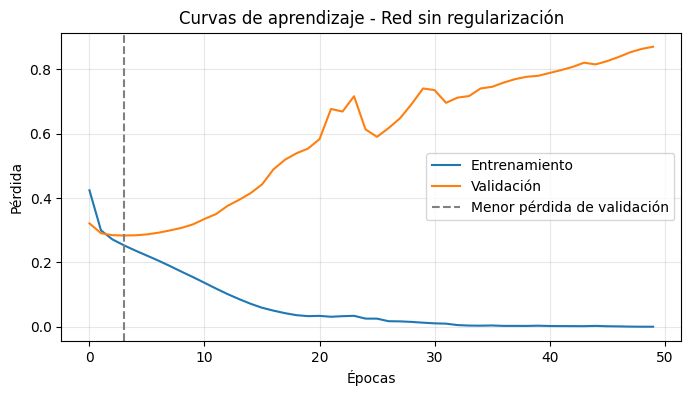

Época con menor pérdida de validación: 4


In [45]:

# UNIDAD II - Curvas de aprendizaje de la red sin freno

import matplotlib.pyplot as plt
import numpy as np

perdida_train = historial_sin_freno.history["loss"]
perdida_val = historial_sin_freno.history["val_loss"]

epoca_mejor = np.argmin(perdida_val) + 1

plt.figure(figsize=(8, 4))
plt.plot(perdida_train, label="Entrenamiento")
plt.plot(perdida_val, label="Validación")
plt.axvline(epoca_mejor - 1, linestyle="--",
            color="gray", label="Menor pérdida de validación")

plt.xlabel("Épocas")
plt.ylabel("Pérdida")
plt.title("Curvas de aprendizaje - Red sin regularización")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print("Época con menor pérdida de validación:", epoca_mejor)


### Análisis del sobreajuste de la red neuronal

La red neuronal presentó su menor pérdida de validación en la época 4. Posteriormente, la pérdida de entrenamiento continuó disminuyendo, mientras que la pérdida de validación aumentó progresivamente. Este comportamiento evidencia sobreajuste, indicando que el modelo aprende los datos de entrenamiento, pero pierde capacidad de generalización. Por ello, se considera necesario aplicar mecanismos de regularización y parada temprana.

In [46]:

# UNIDAD II - Red neuronal con regularizacion

tf.keras.utils.set_random_seed(42)

red_con_freno = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_red_train_nn.shape[1],)),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dropout(0.30),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dropout(0.30),
    tf.keras.layers.Dense(1, activation="sigmoid")
])

red_con_freno.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[tf.keras.metrics.AUC(name="auc")]
)

parada = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

historial_con_freno = red_con_freno.fit(
    X_red_train_nn,
    y_red_train,
    validation_data=(X_red_val_nn, y_red_val),
    epochs=50,
    batch_size=32,
    callbacks=[parada],
    verbose=0
)

# Evaluar el modelo con los mejores pesos recuperados
resultado_train = red_con_freno.evaluate(
    X_red_train_nn, y_red_train, verbose=0
)
resultado_val = red_con_freno.evaluate(
    X_red_val_nn, y_red_val, verbose=0
)

print("Épocas ejecutadas:",
      len(historial_con_freno.history["loss"]))
print("AUC entrenamiento:", round(resultado_train[1], 3))
print("AUC validación:", round(resultado_val[1], 3))


Épocas ejecutadas: 11
AUC entrenamiento: 0.957
AUC validación: 0.937


### Evaluación de la red neuronal con regularización

La red neuronal con Dropout y parada temprana alcanzó un AUC de 0,957 en entrenamiento y 0,937 en validación, utilizando 11 épocas. En comparación con la red sin regularización, presentó una menor diferencia entre ambos conjuntos y mejoró su desempeño de validación. Estos resultados indican una reducción del sobreajuste y una mayor capacidad de generalización.

In [47]:

# UNIDAD II - Comparacion de cuatro redes neuronales

configuraciones = [
    (8, 0.20, 0.001),
    (16, 0.30, 0.001),
    (32, 0.30, 0.0005),
    (64, 0.40, 0.0005)
]

resultados_redes = []
redes_entrenadas = []

for i, (neuronas, dropout, tasa) in enumerate(configuraciones):

    tf.keras.utils.set_random_seed(42 + i)

    red = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(X_red_train_nn.shape[1],)),
        tf.keras.layers.Dense(neuronas, activation="relu"),
        tf.keras.layers.Dropout(dropout),
        tf.keras.layers.Dense(1, activation="sigmoid")
    ])

    red.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=tasa),
        loss="binary_crossentropy",
        metrics=[tf.keras.metrics.AUC(name="auc")]
    )

    parada = tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    )

    historia = red.fit(
        X_red_train_nn, y_red_train,
        validation_data=(X_red_val_nn, y_red_val),
        epochs=50,
        batch_size=32,
        callbacks=[parada],
        verbose=0
    )

    auc_val = red.evaluate(
        X_red_val_nn, y_red_val, verbose=0
    )[1]

    resultados_redes.append([
        i + 1, neuronas, dropout, tasa,
        len(historia.history["loss"]), auc_val
    ])

    redes_entrenadas.append(red)

tabla_redes = pd.DataFrame(
    resultados_redes,
    columns=[
        "Red", "Neuronas", "Dropout",
        "Tasa", "Epocas", "AUC_validacion"
    ]
)

display(tabla_redes.round(3))


,Red,Neuronas,Dropout,Tasa,Epocas,AUC_validacion
0,1,8,0.2,0.001,24,0.931
1,2,16,0.3,0.001,21,0.932
2,3,32,0.3,0.000,22,0.932
3,4,64,0.4,0.000,27,0.933


### Comparación de configuraciones neuronales

Se evaluaron cuatro configuraciones de redes neuronales modificando el número de neuronas, Dropout y tasa de aprendizaje. Los valores AUC de validación oscilaron entre 0,931 y 0,933. La red 4 alcanzó el mayor valor (0,933), aunque las diferencias fueron reducidas. Por tanto, no se evidencia una ventaja importante de aumentar la complejidad de la red y también debe considerarse la parsimonia en la selección final.

In [48]:

# UNIDAD II - Seleccion de la mejor red de R3

indice_mejor = tabla_redes["AUC_validacion"].idxmax()

mejor_red = tabla_redes.loc[indice_mejor]
red_elegida = redes_entrenadas[int(mejor_red["Red"]) - 1]

print("Red seleccionada:", int(mejor_red["Red"]))
print("Neuronas:", int(mejor_red["Neuronas"]))
print("Dropout:", mejor_red["Dropout"])
print("Tasa de aprendizaje:", mejor_red["Tasa"])
print("AUC de validación:",
      round(mejor_red["AUC_validacion"], 4))


Red seleccionada: 4
Neuronas: 64
Dropout: 0.4
Tasa de aprendizaje: 0.0005
AUC de validación: 0.9329


### Selección de la red neuronal

La configuración 4, con 64 neuronas, Dropout de 0,40 y tasa de aprendizaje de 0,0005, obtuvo el mayor AUC de validación (0,9329) entre las cuatro alternativas evaluadas. No obstante, las diferencias fueron pequeñas, por lo que su superioridad no puede considerarse concluyente. Se seleccionó esta configuración para realizar la evaluación final con datos independientes.

In [49]:

# UNIDAD II - Evaluacion final de los modelos

from sklearn.base import clone
from sklearn.metrics import roc_auc_score, confusion_matrix
from scipy import sparse

# Preparar prueba para las redes neuronales
X_prueba_nn = preprocesador.transform(X_test)

if sparse.issparse(X_prueba_nn):
    X_prueba_nn = X_prueba_nn.toarray()

X_prueba_nn = np.asarray(X_prueba_nn, dtype=np.float32)

predicciones = {}

# Modelos tradicionales: ajustar con entrenamiento
for nombre, modelo in [
    ("Elastic Net", modelo_elastic),
    ("Random Forest", modelo_rf)
]:
    ajustado = clone(modelo).fit(X_train, y_train)
    predicciones[nombre] = ajustado.predict_proba(X_test)[:, 1]

# Redes neuronales ya entrenadas
for nombre, red in [
    ("Red sin freno", red_sin_freno),
    ("Red con freno", red_con_freno),
    ("Red elegida R3", red_elegida)
]:
    predicciones[nombre] = red.predict(
        X_prueba_nn, verbose=0
    ).ravel()

# Calcular indicadores con umbral 0.5
resultados = []

for nombre, prob in predicciones.items():
    clases = (prob >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(
        y_test, clases, labels=[0, 1]
    ).ravel()

    resultados.append([
        nombre,
        round(roc_auc_score(y_test, prob), 3),
        fn,
        fp
    ])

tabla_prueba = pd.DataFrame(
    resultados,
    columns=[
        "Modelo", "AUC prueba",
        "Abandonos no detectados",
        "Falsas alarmas"
    ]
)

display(tabla_prueba)


,Modelo,AUC prueba,Abandonos no detectados,Falsas alarmas
0,Elastic Net,0.955,42,44
1,Random Forest,0.953,51,42
2,Red sin freno,0.942,45,69
3,Red con freno,0.953,49,37
4,Red elegida R3,0.955,49,42


### Evaluación final de los modelos predictivos

En la prueba independiente de 908 estudiantes, Elastic Net y la red neuronal seleccionada alcanzaron el mayor AUC (0,955). Elastic Net presentó 42 casos de abandono no detectados y 44 falsas alarmas, mientras que la red seleccionada registró 49 y 42, respectivamente. La red sin regularización obtuvo el menor AUC (0,942) y el mayor número de falsas alarmas (69).

Los resultados muestran un desempeño predictivo similar entre los mejores modelos. Elastic Net constituye una alternativa favorable por su interpretabilidad y menor número de abandonos no detectados, aunque no se ha demostrado una superioridad estadísticamente significativa.

In [50]:

# UNIDAD II - Guardar resultados de prueba final

from pathlib import Path

Path("resultados").mkdir(exist_ok=True)

tabla_prueba.to_csv(
    "resultados/comparacion_final_modelos.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Resultados finales guardados correctamente")
display(tabla_prueba)


Resultados finales guardados correctamente


,Modelo,AUC prueba,Abandonos no detectados,Falsas alarmas
0,Elastic Net,0.955,42,44
1,Random Forest,0.953,51,42
2,Red sin freno,0.942,45,69
3,Red con freno,0.953,49,37
4,Red elegida R3,0.955,49,42


### Comparación final de los modelos

Los resultados de la prueba independiente evidenciaron un desempeño predictivo similar entre Elastic Net y la red neuronal seleccionada, ambos con un AUC de 0,955. Sin embargo, Elastic Net presentó menos casos de deserción no detectados (42 frente a 49) y ofrece una interpretación más sencilla. Por ello, constituye una alternativa favorable para la identificación del riesgo de abandono universitario. Estos resultados corresponden a una evaluación experimental y requieren validación adicional antes de su aplicación práctica.

In [51]:

# UNIDAD II - Evaluacion final de XGBoost y LightGBM

from sklearn.base import clone
from sklearn.metrics import roc_auc_score, confusion_matrix

resultados_adicionales = []

for nombre, modelo in [
    ("XGBoost", modelo_xgb),
    ("LightGBM", modelo_lgbm)
]:
    ajustado = clone(modelo).fit(X_train, y_train)
    probabilidades = ajustado.predict_proba(X_test)[:, 1]
    predichos = (probabilidades >= 0.5).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test, predichos, labels=[0, 1]
    ).ravel()

    resultados_adicionales.append([
        nombre,
        round(roc_auc_score(y_test, probabilidades), 3),
        fn,
        fp
    ])

tabla_adicional = pd.DataFrame(
    resultados_adicionales,
    columns=[
        "Modelo", "AUC prueba",
        "Abandonos no detectados", "Falsas alarmas"
    ]
)

display(tabla_adicional)


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


,Modelo,AUC prueba,Abandonos no detectados,Falsas alarmas
0,XGBoost,0.954,44,41
1,LightGBM,0.953,44,44


### Evaluación final de XGBoost y LightGBM

XGBoost obtuvo un AUC de 0,954, con 44 casos de deserción no detectados y 41 falsas alarmas. LightGBM alcanzó un AUC de 0,953, con 44 abandonos no detectados y 44 falsas alarmas. Ambos modelos mostraron una buena capacidad discriminativa, con resultados similares a Elastic Net y Random Forest. Las pequeñas diferencias observadas no permiten establecer una superioridad estadística concluyente.

In [52]:

# UNIDAD II - Tabla general de resultados

# Unir todas las evaluaciones finales
tabla_final = pd.concat(
    [tabla_prueba, tabla_adicional],
    ignore_index=True
)

# Incorporar los resultados de validacion cruzada
tabla_general = comparacion.merge(
    tabla_final,
    on="Modelo",
    how="outer"
)

# Guardar tabla
tabla_general.to_csv(
    "resultados/tabla_general_unidad_II.csv",
    index=False,
    encoding="utf-8-sig"
)

display(tabla_general.round(3))
print("Tabla general guardada correctamente")


,Modelo,AUC promedio,Desviación,AUC prueba,Abandonos no detectados,Falsas alarmas
0,Elastic Net,0.931,0.014,0.955,42,44
1,LightGBM,0.932,0.012,0.953,44,44
2,Random Forest,0.935,0.009,0.953,51,42
3,Red con freno,NaN,NaN,0.953,49,37
4,Red elegida R3,NaN,NaN,0.955,49,42
5,Red sin freno,NaN,NaN,0.942,45,69
6,XGBoost,0.934,0.009,0.954,44,41


Tabla general guardada correctamente


### Comparación general y selección del modelo

Los siete modelos evaluados mostraron una buena capacidad para distinguir entre estudiantes que abandonaron sus estudios y aquellos que se graduaron. En la prueba final, Elastic Net y la red neuronal seleccionada alcanzaron el mayor AUC (0,955). Sin embargo, Elastic Net registró menos abandonos no detectados (42 frente a 49) y presenta mayor facilidad de interpretación.

Por estas razones, se propone Elastic Net como modelo principal del estudio. Esta elección considera tanto el desempeño predictivo como la simplicidad del modelo, sin asumir diferencias estadísticamente significativas entre los métodos evaluados.